# Judge calibration against MT-Bench experts

How often does the local LLM judge (`judge_pair` from `llm_eval.scorers.judge`) agree with human experts? We judge 200 first-turn pairs from MT-Bench in both orders and compare the result with the human verdict using accuracy, Cohen's kappa and a confusion matrix.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from pydantic import ValidationError
from sklearn.metrics import ConfusionMatrixDisplay, cohen_kappa_score, confusion_matrix

from llm_eval.models import JudgeVerdict, Winner
from llm_eval.providers.ollama import OllamaModel
from llm_eval.results.metrics import agreement
from llm_eval.scorers.judge import JudgeError, judge_pair

DATASET_NAME = "lmsys/mt_bench_human_judgments"
SPLIT = "human"
JUDGE_MODEL = "llama3.2:3b"
SAMPLE_SIZE = 200
SMOKE_SIZE = 20
SEED = 42
LABELS: list[Winner] = ["A", "B", "tie"]
HUMAN_LABELS: dict[str, Winner] = {"model_a": "A", "model_b": "B", "tie": "tie"}
RESULTS_PATH = Path("../results/calibration.csv")
# Judging 200 pairs takes ~25 min on a MacBook; set to True to judge again.
RERUN = False

/Users/patrykczechowski/studia/llm-eval/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Sample 200 first-turn pairs

In [2]:
ds = load_dataset(DATASET_NAME, split=SPLIT)
df = ds.to_pandas()
assert isinstance(df, pd.DataFrame)  # narrows the union type for Pylance

sample = df[df["turn"] == 1].sample(n=SAMPLE_SIZE, random_state=SEED)
pairs = pd.DataFrame(
    {
        "question_id": sample["question_id"],
        "model_a": sample["model_a"],
        "model_b": sample["model_b"],
        "question": sample["conversation_a"].map(lambda conv: conv[0]["content"]),
        "answer_a": sample["conversation_a"].map(lambda conv: conv[1]["content"]),
        "answer_b": sample["conversation_b"].map(lambda conv: conv[1]["content"]),
        "human": sample["winner"].map(HUMAN_LABELS),
    }
).reset_index(drop=True)

pairs["human"].value_counts()

human
A      82
B      72
tie    46
Name: count, dtype: int64

## 2. Run the judge

`RecordingModel` wraps the Ollama model and keeps raw responses, so besides the final `judge_pair` label we also see both single-order verdicts. That shows how often the judge contradicts itself after the answers are swapped. A pair where the judge returns invalid JSON twice is labelled `error`.

In [3]:
class RecordingModel:
    def __init__(self, inner: OllamaModel) -> None:
        self.inner = inner
        self.responses: list[str] = []

    def complete(self, system: str, user: str) -> str:
        response = self.inner.complete(system, user)
        self.responses.append(response)
        return response


def parse_winner(raw: str) -> Winner | None:
    try:
        return JudgeVerdict.model_validate_json(raw).winner
    except ValidationError:
        return None


def judge_all(pairs: pd.DataFrame, model: RecordingModel) -> pd.DataFrame:
    rows = []
    for row in pairs.itertuples():
        model.responses.clear()
        try:
            judge = judge_pair(model, row.question, row.answer_a, row.answer_b)
        except JudgeError:
            judge = "error"
        valid = [w for w in map(parse_winner, model.responses) if w is not None]
        rows.append(
            {
                "judge": judge,
                "first_order": valid[0] if len(valid) > 0 else None,
                "swapped_order": valid[1] if len(valid) > 1 else None,
                "calls": len(model.responses),
            }
        )
    return pd.concat([pairs, pd.DataFrame(rows)], axis=1)


model = RecordingModel(OllamaModel(JUDGE_MODEL))

Smoke run on the first 20 pairs to check that everything works end to end.

In [4]:
if RERUN or not RESULTS_PATH.exists():
    smoke = judge_all(pairs.head(SMOKE_SIZE), model)
    print(smoke["judge"].value_counts())

judge
B      8
tie    8
A      4
Name: count, dtype: int64


Full run. Results are saved to `results/calibration.csv`, so later runs only load them.

In [5]:
if RERUN or not RESULTS_PATH.exists():
    start = time.perf_counter()
    results = judge_all(pairs, model)
    print(f"Judged {len(results)} pairs in {time.perf_counter() - start:.0f} s")
    RESULTS_PATH.parent.mkdir(exist_ok=True)
    results.drop(columns=["question", "answer_a", "answer_b"]).to_csv(
        RESULTS_PATH, index=False
    )

results = pd.read_csv(RESULTS_PATH)
results.head()

Judged 200 pairs in 3034 s


,question_id,model_a,model_b,human,judge,first_order,swapped_order,calls
0,127,vicuna-13b-v1.2,gpt-3.5-turbo,B,tie,A,A,2
1,159,alpaca-13b,gpt-3.5-turbo,B,B,B,A,2
2,116,claude-v1,gpt-3.5-turbo,tie,tie,B,B,2
3,149,alpaca-13b,llama-13b,tie,A,A,B,2
4,116,llama-13b,gpt-4,B,B,B,A,2


## 3. Accuracy and Cohen's kappa

In [6]:
valid = results[results["judge"] != "error"]
human = valid["human"].tolist()
judge = valid["judge"].tolist()

metrics = pd.DataFrame(
    {
        "value": [
            len(results),
            (results["judge"] == "error").sum(),
            agreement(judge, human),
            cohen_kappa_score(human, judge, labels=LABELS),
        ]
    },
    index=["pairs", "judge errors", "accuracy", "cohen kappa"],
)
metrics.round(3)

,value
pairs,200.000
judge errors,0.000
accuracy,0.470
cohen kappa,0.227


## 4. Confusion matrix

In [7]:
cm = confusion_matrix(human, judge, labels=LABELS)
pd.DataFrame(
    cm,
    index=[f"human {label}" for label in LABELS],
    columns=[f"judge {label}" for label in LABELS],
)

,judge A,judge B,judge tie
human A,39,9,34
human B,6,32,34
human tie,9,14,23


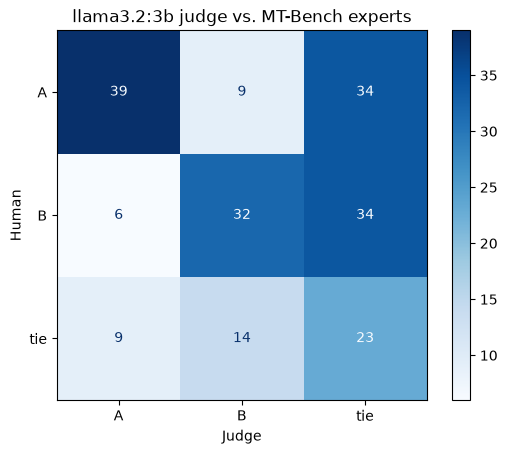

In [8]:
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues")
plt.title(f"{JUDGE_MODEL} judge vs. MT-Bench experts")
plt.xlabel("Judge")
plt.ylabel("Human")
plt.show()

## 5. Label distribution and position bias

In [9]:
distribution = pd.DataFrame(
    {
        "human": results["human"].value_counts(normalize=True),
        "judge": results["judge"].value_counts(normalize=True),
    }
).fillna(0)
(distribution * 100).round(1)

,human,judge
A,41.0,27.0
B,36.0,27.5
tie,23.0,45.5


In [10]:
both = results.dropna(subset=["first_order", "swapped_order"])
swap_back: dict[str, str] = {"A": "B", "B": "A", "tie": "tie"}
consistent = (both["first_order"] == both["swapped_order"].map(swap_back)).mean()
# "A" in a single-order verdict always means "the answer shown first".
first_shown = pd.concat([both["first_order"], both["swapped_order"]])
prefers_first = (first_shown == "A").mean()
prefers_second = (first_shown == "B").mean()

print(f"Consistent after swapping the order: {consistent:.1%}")
print(f"Single-order verdicts picking the answer shown first: {prefers_first:.1%}")
print(f"Single-order verdicts picking the answer shown second: {prefers_second:.1%}")

Consistent after swapping the order: 54.5%
Single-order verdicts picking the answer shown first: 56.2%
Single-order verdicts picking the answer shown second: 43.8%


## Conclusions

1. **Agreement with experts is only fair.** Accuracy is 47% and Cohen's kappa 0.23 (the 0.21–0.40 band is usually read as "fair" agreement). The judge never failed to return valid JSON (7 of 200 pairs needed the single retry), so the weak result comes from the judgments themselves, not from parsing.
2. **When `llama3.2:3b` names a winner, it is usually right; the problem is ties.** A picked winner matches the experts in 72% (A) and 58% (B) of cases, and the judge chose the opposite winner in only 15 of 154 decisive pairs. But it returns `tie` for 45.5% of pairs versus 23% for humans, turning 68 decisive pairs into ties, and only 25% of its ties are real ties.
3. **Position bias is strong, and the swap rule converts it into ties.** Only 54.5% of pairs get the same verdict after the answers are swapped, and single-order verdicts pick the answer shown first 56% of the time. Every `tie` in the results comes from such a contradiction: the model never said `tie` in both orders. The swap protects us from wrong winners but costs recall. Next steps: a larger judge (`llama3.1:8b` or Claude in lesson 13), forced JSON schema, and checking whether "A wins in one order, tie in the other" should count as a win for A.